# Quick Structure Visualization: 

- This tutorial shows how to visualize the atoms and bonds in a strucutre  
- Although mofography is not meant to be a visualization tool, it can be quite handy for visualizing exactly what you want to show using a Plotly backend. 
- It can be used in a jupyter notebook or in python scripts and turned into interactive html plots of the structure to share with your collaborators. 
- mofography includes routines to visualize outputs of the RASPA simulation code, we will explore some of that as well.


Note: Although not a prerequisite, checking out the Basic Structure Operations tutorial would be handy in making the most out this tutorial.

## General theme of plotting in mofography

This is the plotting workflow in mofography:
- Initialize a Plotly figure
- Make the plotting traces using some functions in mofography. Unless specified, mofography functions always return a trace, and not a figure object. We think that this adds more flexibility to the plotting process.
- Add the traces to the figure object, along with any of your other traces. 
- Modify the styling of the figure: You will probably be using Plotly for that, which is infinitely customizable. In some cases there are some handy layouts provided in mofography for shortcuts, as we will see later.
- show the figure in a browser or your notebook or save it as an html or image file. 

I highly recommend checking out the Plotly documentation for more information on how to customize your plots, which is here: https://plotly.com/python/

and the mofography API documentation to find all the additional options within the plotting functions that may only be glossed over here

### Tips and tricks #1: 
All the framework traces in mofography (atoms, bonds etc.) are actually 3D meshes (spheres, cylinders etc.) that are built on a Trimesh backend. Hence while they look good, can be a bit taxing on the CPU/GPU. Hence, you may want to play with the resolution of the meshes, perhaps keep it low for quick visualizations and then increase it for publication quality figures.

## Imports

Let's set some paths  and import mofography.

There are more materials in the `TestCIFs` folder, so feel free to explore those as well.

Change renderer to 'notebook_connected' or 'browser' for an interactive plot.



In [1]:
import sys
import os
# * Put your path here
path_to_mgr = os.path.abspath(
    'c:/Users/Arun Gopalan/OneDrive - The University of Manchester/my_cloned_repos/mofography')
sys.path.append(path_to_mgr)
import mofography as mgr


path_to_cif = os.path.join(path_to_mgr, 'examples', 'TestCIFs', 'P1-IRMOF-1.cif')


import plotly.io as pio 
pio.renderers.default = "png"

Let's start by reading in a structure using ASE 

In [2]:
from ase.io import read 
mat_atoms = read('../examples/TestCIFs/P1-IRMOF-1.cif')

c:\Users\Public\anaconda3\envs\jl_env\lib\site-packages\ase\io\cif.py:401: UserWarning:

crystal system 'triclinic' is not interpreted for space group Spacegroup(1, setting=1). This may result in wrong setting!



## Quick visualization

Let's compute the covalent bonds in the structure and turn it into a mesh quickly using a built-in function. 

In [3]:
import mofography as mgr 
mat_updated = mgr.update_with_covalent_bonds(mat_atoms)
frame_mesh = mgr.plot_framework_as_mesh(mat_updated)

c:\Users\Public\anaconda3\envs\jl_env\lib\site-packages\ase\atoms.py:967: VisibleDeprecationWarning:

Use get_global_number_of_atoms() instead



No node props provided, using default set: [position, scaled_position, element and atomic_number]
No edge properties provided. Use the default set: [bond_order, bond_type]
isomorphic aromatic cycles is None, trying to calculate


c:\Users\Arun Gopalan\OneDrive - The University of Manchester\my_cloned_repos\mofography\mofography\visualize.py:767: UserWarning:

Optimal rotation is not uniquely or poorly defined for the given sets of vectors.



Finally, let's visualize the structure using Plotly.


In [4]:
import plotly.graph_objects as go
fig = go.Figure(data=[*frame_mesh])
fig.show(renderer="notebook_connected")

### Tips and tricks #2:
Note the little `*` in front of the `frame_mesh` object in figure initalization line? the `plot_framework_as_mesh` routines returns a list of traces, namely the atoms and bonds. We are simply unpacking the list into separate variables here. If you forget that little `*` you will get an error.

Although this looks fine, we might want to remove the annoying background and make it look pure white or dark. You can do this easily using Plotly's layout options. However, mofography provides a couple of preset layouts for quick use. 

Let's try the white layout first,

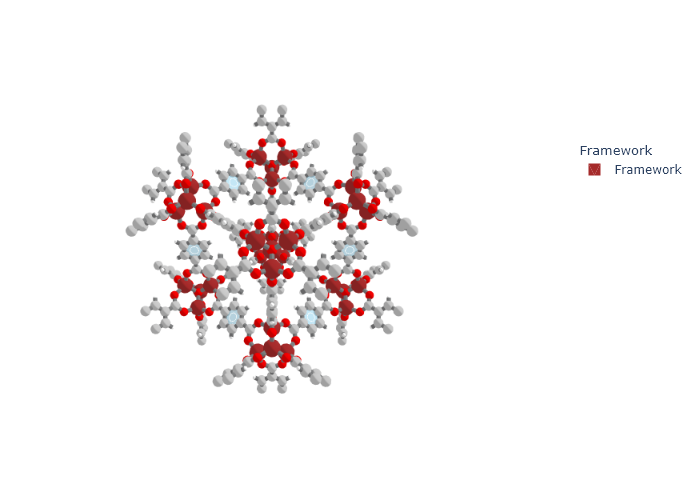

In [5]:
fig.update(layout=mgr.white_layout).show()

and now the dark layout,

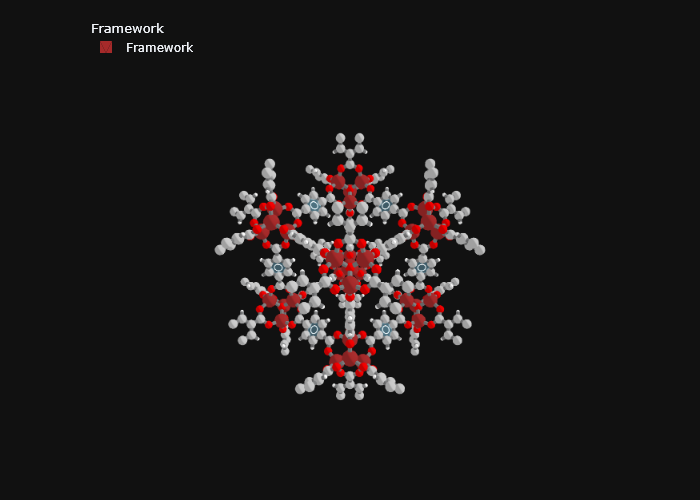

In [6]:
fig.update(layout=mgr.dark_layout).show()

note that we haven't shown the unit cell here, but you can easily add it using the `plot_cell` function.

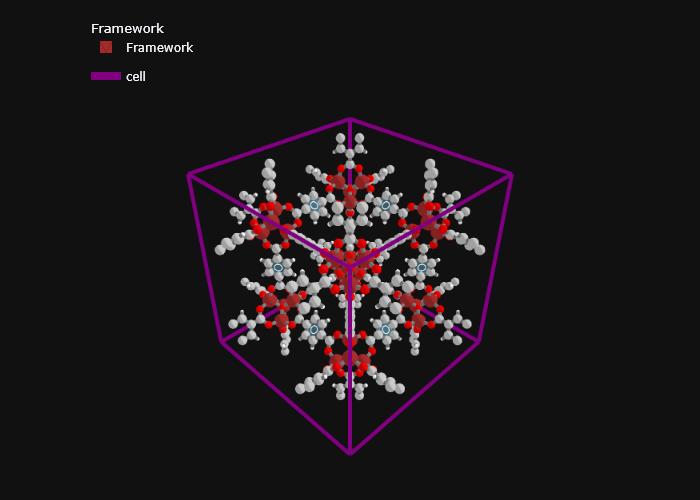

In [7]:
fig.add_trace(mgr.plot_cell(mat_updated)).show()

## Tips and tricks #3:
Notice that the lighting here looks kinda shabby, you can change that also using Plotly https://plotly.com/python/reference/mesh3d/#mesh3d-lighting

But, if you want a lighting combination that works on short notice, you may use the `stylize=True` option in the `plot_framework_as_mesh` function. Note that this is available in all of mofography's mesh plotting functions. Try it out yourself and see what happens.